# Camera Calibration

Scale factor between distorted and undistorted: 1.0299625835018675


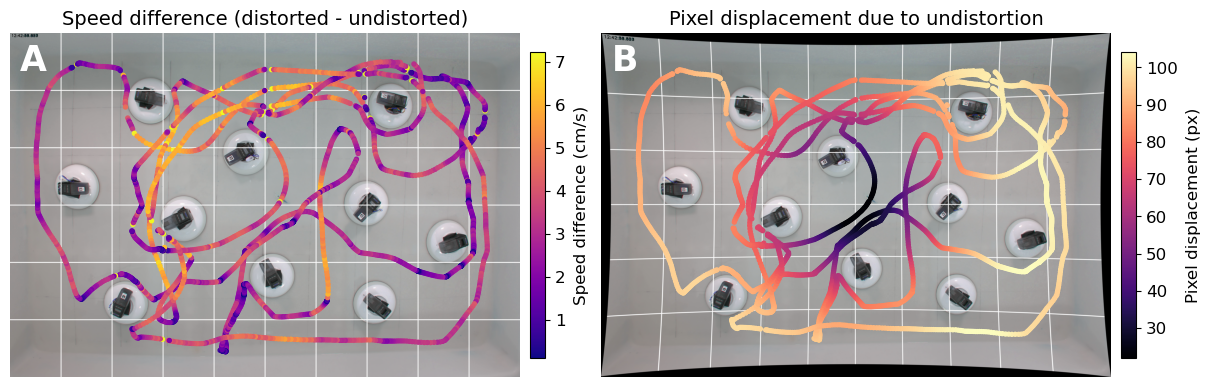

In [13]:
#!/usr/bin/env python3

import glob

import cv2
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
from scipy.interpolate import griddata

# -------------------------------------------------
# User paths
# -------------------------------------------------
settings_file = "./config.settings"
input_dir = "./20251210_124144_000/data/"
background_image = "./20251210_124144_000/average_basler_record_20251210_124144_000.png"

TRACK_INDEX = 2

# -------------------------------------------------
# Load config
# -------------------------------------------------
def load_config(path):
    cfg = {}
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            k, v = line.split("=", 1)
            k = k.strip()
            v = v.strip()

            if v.lower() in ("true", "false"):
                cfg[k] = v.lower() == "true"
            elif v.startswith('"'):
                cfg[k] = v.strip('"')
            elif v.startswith("["):
                cfg[k] = eval(v)
            else:
                try:
                    cfg[k] = float(v)
                except ValueError:
                    cfg[k] = v
    return cfg


cfg = load_config(settings_file)

# -------------------------------------------------
# Load trajectory
# -------------------------------------------------
files = sorted(glob.glob(input_dir + "*id*.npz"))
with np.load(files[TRACK_INDEX]) as npz:
    X = npz["X#wcentroid"] / cfg["cm_per_pixel"]
    Y = npz["Y#wcentroid"] / cfg["cm_per_pixel"]
    frame = npz["frame"]
    missing = npz["missing"].astype(bool)

mask = ~missing & np.isfinite(X) & np.isfinite(Y)
X, Y, frame = X[mask], Y[mask], frame[mask]

order = np.argsort(frame)
X, Y, frame = X[order], Y[order], frame[order]


# -------------------------------------------------
# Speed computation
# -------------------------------------------------
def compute_speed(X, Y, frame):
    dX = np.diff(X)
    dY = np.diff(Y)
    dt = np.diff(frame)
    S = np.sqrt(dX**2 + dY**2) / dt
    return np.insert(S, 0, np.nan)

fps = 10
S_dist = compute_speed(X, Y, frame) * cfg["cm_per_pixel"] * fps

# -------------------------------------------------
# Draw grid
# -------------------------------------------------
def draw_grid(img, nx, ny, color=(0, 255, 0), thickness=1):
    """
    Draws a perfectly symmetric grid on an image.

    img: np.ndarray (H, W, 3)
    nx: number of columns
    ny: number of rows
    """
    h, w = img.shape[:2]
    out = img.copy()

    dx = w / nx
    dy = h / ny

    # Vertical lines
    for i in range(1, nx):
        x = int(round(i * dx))
        cv2.line(out, (x, 0), (x, h), color, thickness)

    # Horizontal lines
    for j in range(1, ny):
        y = int(round(j * dy))
        cv2.line(out, (0, y), (w, y), color, thickness)

    return out

# -------------------------------------------------
# Undistort points
# -------------------------------------------------
mtx = np.asarray(cfg["cam_matrix"], dtype=np.float32)
dist = np.asarray(cfg["cam_undistort_vector"], dtype=np.float32)

img_cv = cv2.imread(background_image)
img_cv = draw_grid(img_cv, nx=10, ny=6, color=(255,255,255), thickness=5)

# BGR → RGB
img = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)

# uint8 → float32 in [0, 1]
img = img.astype(np.float32) / 255.0

h, w = img.shape[:2]

newK, _ = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), 1, (w, h))

pts = np.column_stack((X, Y)).astype(np.float32).reshape(-1, 1, 2)

pts_u = cv2.undistortPoints(pts, cameraMatrix=mtx, distCoeffs=dist, P=newK)

Xu = pts_u[:, 0, 0]
Yu = pts_u[:, 0, 1]

mask_u = np.isfinite(Xu) & np.isfinite(Yu)
Xu, Yu = Xu[mask_u], Yu[mask_u]

# Original distance in pixels
d_orig_px = np.sqrt((X[1]-X[0])**2 + (Y[1]-Y[0])**2)

# Undistorted distance in pixels
d_undist_px = np.sqrt((Xu[1]-Xu[0])**2 + (Yu[1]-Yu[0])**2)

# Compare
scale_change = d_undist_px / d_orig_px
print("Scale factor between distorted and undistorted:", scale_change)

S_undist = compute_speed(Xu, Yu, frame) * cfg["cm_per_pixel"] * fps
S_undist = S_undist * (newK[0,0]/mtx[0,0])
S_diff = S_dist - S_undist
S_diff = S_diff[mask_u]
# S_diff = 100 * (S_dist - S_undist) / S_dist

# Displacement in pixels between distorted and undistorted positions
disp_px = np.sqrt((Xu - X)**2 + (Yu - Y)**2)

# -------------------------------------------------
# Load and undistort background
# -------------------------------------------------
img_u = cv2.undistort(img, mtx, dist, None, newK)

# -------------------------------------------------
# Publication-ready plotting
# -------------------------------------------------
plt.rcParams.update(
    {
        "font.size": 12,
        "font.family": "sans-serif",
        "axes.titlesize": 14,
        "axes.labelsize": 12,
    }
)

fig, axs = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)

# Percentile-based color limits
vmin_dist, vmax_dist = np.nanpercentile(S_dist, [1, 99])
vmin_diff, vmax_diff = np.nanpercentile(S_diff, [1, 99])
vmin_disp, vmax_disp = np.nanpercentile(disp_px, [1, 99])

# Distorted
# axs[0].imshow(img)
# sc0 = axs[0].scatter(
#     X, Y, s=8, c=S_dist, cmap="viridis", vmin=vmin_dist, vmax=vmax_dist
# )
# axs[0].set_title("Distorted (speed)")
# axs[0].axis("off")
# cbar0 = fig.colorbar(sc0, ax=axs[0], fraction=0.03, pad=0.02)
# cbar0.set_label("Speed (cm/s)", labelpad=6)

# Difference
axs[0].imshow(img)
sc0 = axs[0].scatter(
    X, Y, s=8, c=S_diff, cmap="plasma", vmin=vmin_diff, vmax=vmax_diff
)
axs[0].set_title("Speed difference (distorted - undistorted)")
axs[0].axis("off")
cbar0 = fig.colorbar(sc0, ax=axs[0], fraction=0.03, pad=0.02)
cbar0.set_label("Speed difference (cm/s)", labelpad=6)

# Displacement
axs[1].imshow(img_u)
sc1 = axs[1].scatter(
    Xu, Yu, s=8, c=disp_px, cmap="magma", vmin=vmin_disp, vmax=vmax_disp
)
axs[1].set_title("Pixel displacement due to undistortion")
axs[1].axis("off")
cbar1 = fig.colorbar(sc1, ax=axs[1], fraction=0.03, pad=0.02)
cbar1.set_label("Pixel displacement (px)", labelpad=6)

# Contour Lines
# Filter out NaNs
# valid_mask = np.isfinite(Xu) & np.isfinite(Yu) & np.isfinite(S_diff)
# x_pts = Xu[valid_mask]
# y_pts = Yu[valid_mask]
# values = S_diff[valid_mask]

# # Create RBF interpolator
# from scipy.interpolate import Rbf
# rbf = Rbf(x_pts, y_pts, values, function='thin_plate', smooth=5)

# factor = 10  # increase this to lower resolution more
# xi = np.arange(0, w, factor)
# yi = np.arange(0, h, factor)
# XI, YI = np.meshgrid(xi, yi)
# ZI = rbf(XI, YI)
# contour_levels = np.nanpercentile(values, [25, 50, 75])
# colors = ['cyan', 'magenta', 'yellow']  # same length as contour_levels
# axs[1].contour(XI, YI, ZI, levels=contour_levels, colors=colors, linewidths=1.2)

# For panel A (left plot)
axs[0].text(
    0.02,
    0.97,  # x, y in axes coordinates (0-1)
    "A",
    transform=axs[0].transAxes,
    fontsize=25,
    fontweight="bold",
    va="top",
    ha="left",
    color="white",
)

# For panel B (right plot)
axs[1].text(
    0.02,
    0.97,
    "B",
    transform=axs[1].transAxes,
    fontsize=25,
    fontweight="bold",
    va="top",
    ha="left",
    color="white",
)

# Save figure for publication
plt.savefig("trajectory_comparison_600dpi.pdf", dpi=600, bbox_inches="tight")
plt.show()

## Quality Assessment
# cx, cy = w/2, h/2
# r = np.sqrt((X - cx)**2 + (Y - cy)**2)
# plt.scatter(r, S_diff, s=5)
# plt.xlabel('Distance from image center (px)')
# plt.ylabel('Speed difference (cm/s)')
# plt.show()

# S_ratio = S_undist / S_dist
# plt.scatter(r, S_ratio, s=5)
# plt.xlabel('Distance from center (px)')
# plt.ylabel('Speed ratio (undistorted / distorted)')
# plt.show()

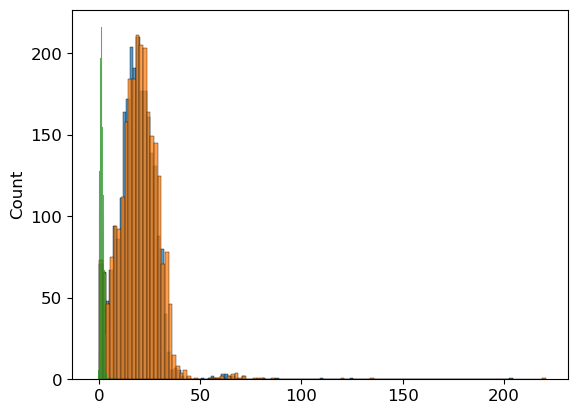

Median Speed [Distorted]: 19.69857 cm/s
Median Speed [Undistorted]: 18.437977 cm/s
Median Speed Difference [Distorted - Unidistorted]: 1.2187853 cm/s


In [31]:
import seaborn as sns

fps = 10
speed_cm_s_undist = S_undist
speed_cm_s_dist = S_dist
speed_cm_s_diff = S_diff

fig, ax = plt.subplots()
sns.histplot(speed_cm_s_undist, ax=ax)
sns.histplot(speed_cm_s_dist, ax=ax)
sns.histplot(speed_cm_s_diff, ax=ax)
plt.show()

print("Median Speed [Distorted]:", np.nanmedian(speed_cm_s_dist), "cm/s")
print("Median Speed [Undistorted]:", np.nanmedian(speed_cm_s_undist), "cm/s")
print("Median Speed Difference [Distorted - Unidistorted]:", np.nanmedian(speed_cm_s_diff), "cm/s")